# DCIS study — HEDeST on the Visium FFPE Human Breast Cancer slide

Single-cell cell types inferred by HEDeST from spot-level deconvolution, on the 10x Visium
FFPE human breast cancer slide, and the neighbourhood ("niche") analysis built on top of
them.

## The run

HEDeST is **not trained here**. This notebook reads back the unperturbed reference run of
the segmentation-agreement study
(`review/segmentation/out/models/Breast/deconv/HoVerNet/perturb_0/`), which is the same
slide, the same proportions and the current optimal parameters:

| | |
|---|---|
| segmentation | **HoVer-Net**, `seg_json/pannuke_fast_mask_lvl3.json`, 45,237 nuclei |
| perturbation | **none** — `perturb_0` is the unperturbed reference, so every detected cell is in |
| proportions | **`DestVI_BRCA_prop.csv`**, the DestVI deconvolution sitting next to this notebook |
| features | **H-Optimus-0**, tile inference with per-cell pooling, 1536 dimensions |
| parameters | `hidden 1024-512, norm, dropout 0, α 0.01, β 0, lr 1e-4, L2, PPSA interpolated` |
| seeds | **5** (0–4), aggregated: the predictions are the mean over seeds |
| mpp | **0.3448** µm/px, measured as 100 µm over the median spot pitch |

Those parameters are the combination the semi-simulation gridsearch elected
(`norm1_do0_a0.01_lr0.0001_l2_hd1024-512`), and they are also the package defaults.

### What differs from the first version of this study

The original notebook read a single-seed run with `hidden 512-256` and `α 0`. Everything
here is the same analysis on a better run, so the numbers move and, in particular, the
clusters of the niche analysis are not the same objects as before. Two consequences are
called out where they happen:

* the niche merge is **computed** (the closest pair of centroids) instead of hard-coded, so
  it still holds if the clustering shifts again;
* the whole-slide niche view is a **cell-type map** rather than scaled contours — at that
  zoom a nucleus is under a pixel, which is exactly the case the map exists for.

Nothing from the original analysis was dropped. The plots added on top of it are marked
**(new)**, and most of them are only possible because this run has five seeds and keeps
both its raw and its adjusted predictions.

In [1]:
%load_ext autoreload
%autoreload 2
%config InlineBackend.figure_format = "png"

import sys
from itertools import chain
from pathlib import Path

# Run this notebook from its own folder: `hedest` is imported from the repository, which is
# two levels up, exactly as the first version of this study did.
REPO = Path.cwd().parents[1]
assert (REPO / "hedest").is_dir(), f"expected the repository at {REPO}; run this notebook from case_study/breast_study/"
sys.path[:0] = [str(REPO), str(REPO / "external")]

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import torch
import yaml
from matplotlib import rcParams
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors

sns.set_context("talk")
sns.set_style("whitegrid")

DATA = Path("/cluster/CBIO/data1/lgortana/Visium_FFPE_Human_Breast_Cancer")
RUN = REPO / "review/segmentation/out/models/Breast/deconv/HoVerNet/perturb_0"
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

ADATA_NAME = "Visium_FFPE_Human_Breast_Cancer"
MPP = 0.3448  # measured: 100 um / median spot pitch

# The three windows the original study looked at, as ((x, y), (width, height)) in level-0 px.
WINDOW_CROP = ((9500, 10500), (2000, 2000))
WINDOW_DELAUNAY = ((18500, 12000), (2500, 2500))
WINDOW_SLIDE = ((4900, 3400), (18800, 19900))


# Writes a figure to figures/ as PNG and SVG, closes it and returns it.
#
# Closing is what keeps every figure displayed exactly once: the hedest plotting functions
# already return closed figures, and the inline backend draws anything still open at the
# end of a cell on top of the cell's own value.
#
# 200 dpi, not 300: the windowed views come from regions of 2,000 to 4,000 px drawn in a
# figure of 11 to 12 inches, so their native resolution is 180 to 330 dpi and anything above
# that is upscaling. And a scatter or a line collection with thousands of elements becomes
# thousands of XML nodes in an SVG -- the whole-slide maps and the Delaunay graph reach tens
# of megabytes that way -- so the dense artists are flagged as rasterized, which embeds them
# as one image layer and leaves the text and the axes vector.
def _element_count(artist):
    # get_segments first: a LineCollection also answers get_offsets, with a single dummy
    # offset, which would hide its thousands of segments.
    for accessor in ("get_segments", "get_offsets", "get_paths", "get_xdata"):
        try:
            values = getattr(artist, accessor)()
        except (AttributeError, TypeError):
            continue
        if values is not None and len(values):
            return len(values)

    return 0


def save(fig, name, dpi=200, rasterize_over=2000):
    for ax in fig.axes:
        for artist in (*ax.collections, *ax.lines):
            if _element_count(artist) > rasterize_over:
                artist.set_rasterized(True)

    for suffix in ("png", "svg"):
        fig.savefig(FIGURES / f"{name}.{suffix}", dpi=dpi, bbox_inches="tight")
    plt.close(fig)

    return fig

/cluster/CBIO/home/lgortana/anaconda3/envs/hedest-env/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Load data

The analysis needs the run, the slide, the segmentation, the AnnData and the cell crops.
Everything is read where it lives; nothing is copied into this folder except the
deconvolution and the GeoJSON exports.

The colours are the ones the slide was exported with
(`Visium_FFPE_Human_Breast_Cancer/colors_dict.yaml`), so a cell type keeps the same colour
here, in QuPath and in every other figure of the project.

In [2]:
from hedest.analysis import PredAnalyzer, load_run
from hedest.analysis.palette import Palette, palette_from_yaml

palette = palette_from_yaml(yaml.safe_load(open(DATA / "colors_dict.yaml")))
run = load_run(RUN)
ct_list = run.ct_list

print(run)
print(palette)
assert palette.names == ct_list, "the palette and the prediction columns must be in the same order"

2026-10-14 14:26:41.639 | INFO     | hedest.analysis.loaders:load_run:233 - Loading /cluster/CBIO/home/lgortana/HEDeST/review/segmentation/out/models/Breast/deconv/HoVerNet/perturb_0/info_aggregated.pickle


HedestRun(perturb_0, 45237 cells, 8 cell types, 2170 spots, 5 seeds, adjusted=True)
Palette(8 cell types: B-cells, CAFs, Cancer Epithelial, Endothelial, Myeloid, PVL, Plasmablasts, T-cells)


In [3]:
from hedest.utils import load_spatial_adata

adata = load_spatial_adata(str(DATA / "adata.h5ad"))

# Nucleus crops, 64 px at 20 um, keyed by cell id. ~570 MB, so this is the slow cell.
image_dict = torch.load(DATA / "image_dict_64px_20um.pt", map_location="cpu", weights_only=False)

# The spot proportions HEDeST was supervised by, as published next to this notebook.
spot_prop_df = pd.read_csv("DestVI_BRCA_prop.csv", index_col=0)
spot_prop_df.index = spot_prop_df.index.astype(str)

adata, spot_prop_df.shape

/cluster/CBIO/home/lgortana/anaconda3/envs/hedest-env/lib/python3.9/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


(AnnData object with n_obs × n_vars = 2518 × 17943
     obs: 'in_tissue', 'array_row', 'array_col'
     var: 'gene_ids', 'feature_types', 'genome'
     uns: 'spatial'
     obsm: 'spatial',
 (2518, 8))

We then build the analyzer object, which is the entry point to every plot below:

In [4]:
analyzer = PredAnalyzer(
    run,
    seg=str(DATA / "seg_json/pannuke_fast_mask_lvl3.json"),
    slide_path=str(DATA / "pyr_tif/Visium_FFPE_Human_Breast_Cancer_image.tif"),
    adata=adata,
    adata_name=ADATA_NAME,
    image_dict=image_dict,
    mpp=MPP,
    palette=palette,
)
analyzer

PredAnalyzer(45237 cells, 8 cell types, 2170 spots, adjusted=True, attached=[seg, slide, adata, crops])

In [5]:
analyzer.describe()

,value
run,perturb_0
cells,"45,237"
cells in spots,"12,299 (27.2%)"
cell types,8
spots with cells,"2,170"
spots in proportions,"2,518"
predictions,adjusted (PPSA)
seeds,5
hidden_dims,"[1024, 512]"
norm,True


In [6]:
analyzer.celltype_summary()

,n_cells,fraction,deconv_fraction,min_prob,median_prob,mean_prob,max_prob,mean_prob_all_cells,mean_agreement
cell_type,,,,,,,,,
B-cells,962,0.021266,0.066900,0.189663,0.388646,0.398531,0.824328,0.062690,0.709356
CAFs,9372,0.207176,0.189359,0.185688,0.571223,0.580265,0.993059,0.164667,0.895988
Cancer Epithelial,13877,0.306762,0.227621,0.191556,0.911653,0.846488,0.988823,0.282081,0.982345
Endothelial,4237,0.093662,0.102112,0.180275,0.552945,0.573973,0.981057,0.104974,0.873071
Myeloid,11414,0.252316,0.231771,0.196543,0.584208,0.607976,0.993840,0.203561,0.899334
PVL,1406,0.031081,0.064106,0.205505,0.502413,0.548772,0.982592,0.054545,0.826885
Plasmablasts,3632,0.080288,0.088740,0.184166,0.550742,0.595222,0.995320,0.089739,0.864482
T-cells,337,0.007450,0.029391,0.173446,0.343713,0.343716,0.551231,0.037743,0.635015


## How solid are the predictions? **(new)**

The original study had one seed, so neither of the next two plots was available.

The run is an aggregate of five seeds, which gives a per-cell **agreement**: the share of
seeds that voted for the majority cell type. Together with the winning probability and the
entropy of the whole vector, it says how decided a prediction is — and therefore how much
of the spatial structure below is signal.

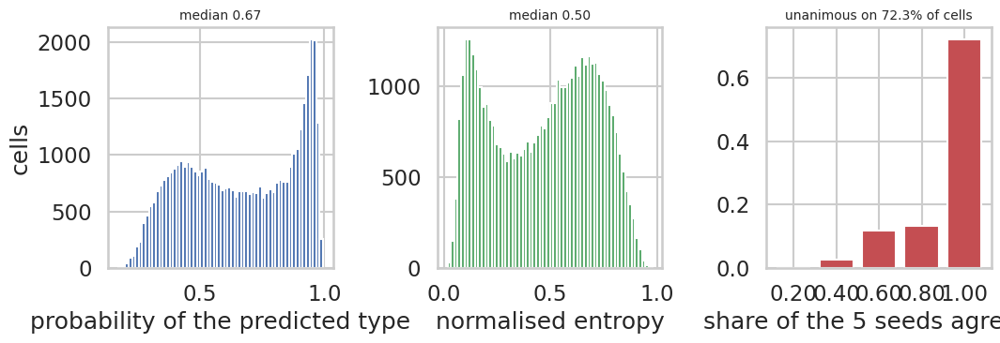

In [7]:
save(analyzer.plot_confidence(), "confidence")

And Prior Probability Shift Adjustment is applied to every cell here (`interpolated`,
ungated), so it is worth seeing what it changed: the composition before and after, and
where the cells that switched type went.

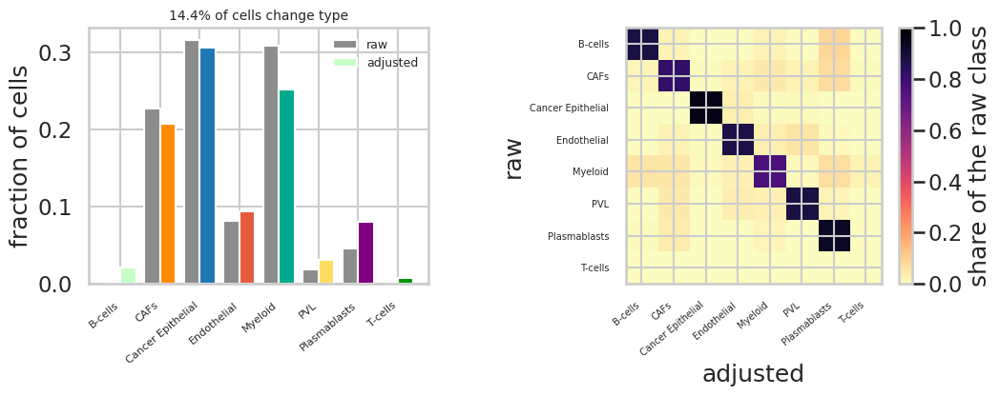

In [8]:
save(analyzer.plot_adjustment_effect(), "adjustment_effect")

# Deconvolution analysis

Before looking at the HEDeST predictions, let's have a look at some basic plots we can make
directly from deconvolution results. The first plot is a co-localization matrix.
Correlation between cell types A and B is equal to the Pearson Correlation between the
proportion vector of A and the proportion vector of B:

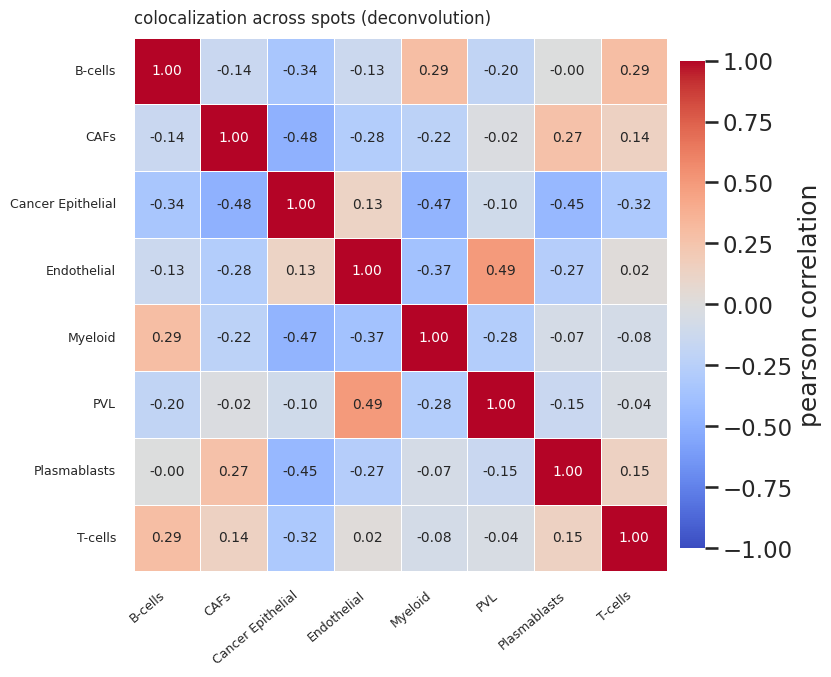

In [9]:
save(analyzer.plot_colocalization_matrix(source="deconvolution"), "coloc_matrix")

The same matrix on the **HEDeST** proportions **(new)**: the proportions recomputed per spot
from the single-cell predictions. Where the two matrices agree, HEDeST has kept the
co-localization structure of the deconvolution; where they differ, it has resolved a spot
differently from the mixture it was given.

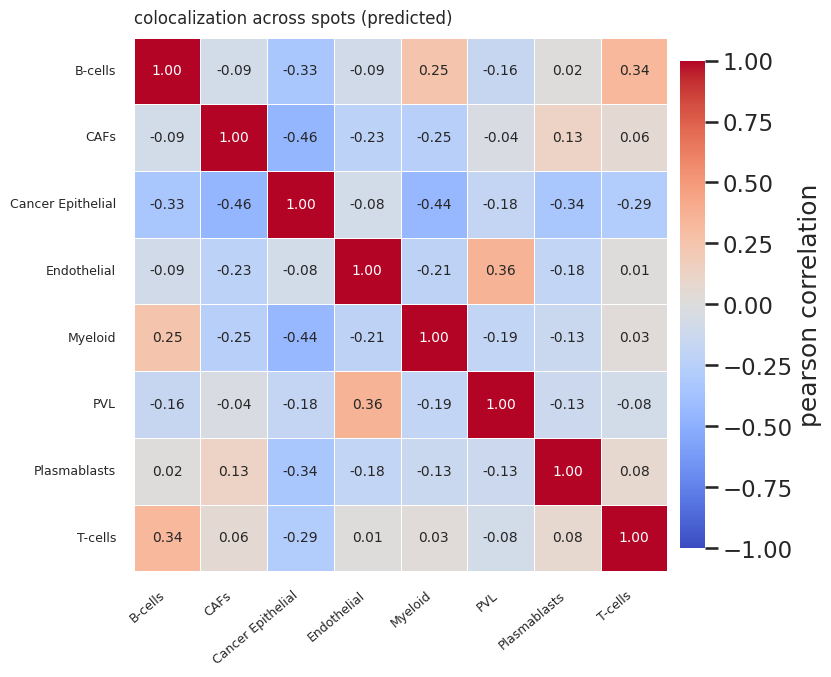

In [10]:
save(analyzer.plot_colocalization_matrix(source="predicted"), "coloc_matrix_predicted")

We can also plot the predicted proportions directly on the histological slide. The colours
come from the palette loaded above, so the pies, the nuclei and the GeoJSON exports all
agree.

In [11]:
viewer = analyzer.visualizer()
viewer

2026-10-14 14:27:44.321 | INFO     | hedest.analysis.postseg:_load_segmentation:245 - Loaded 45237 nuclei from the segmentation.


SlideVisualizer(slide=/cluster/CBIO/data1/lgortana/Visium_FFPE_Human_Breast_Cancer/pyr_tif/Visium_FFPE_Human_Breast_Cancer_image.tif, dimensions=(27452, 25233), mpp=0.3448, cells=45237, spots=2518, labelled=yes)

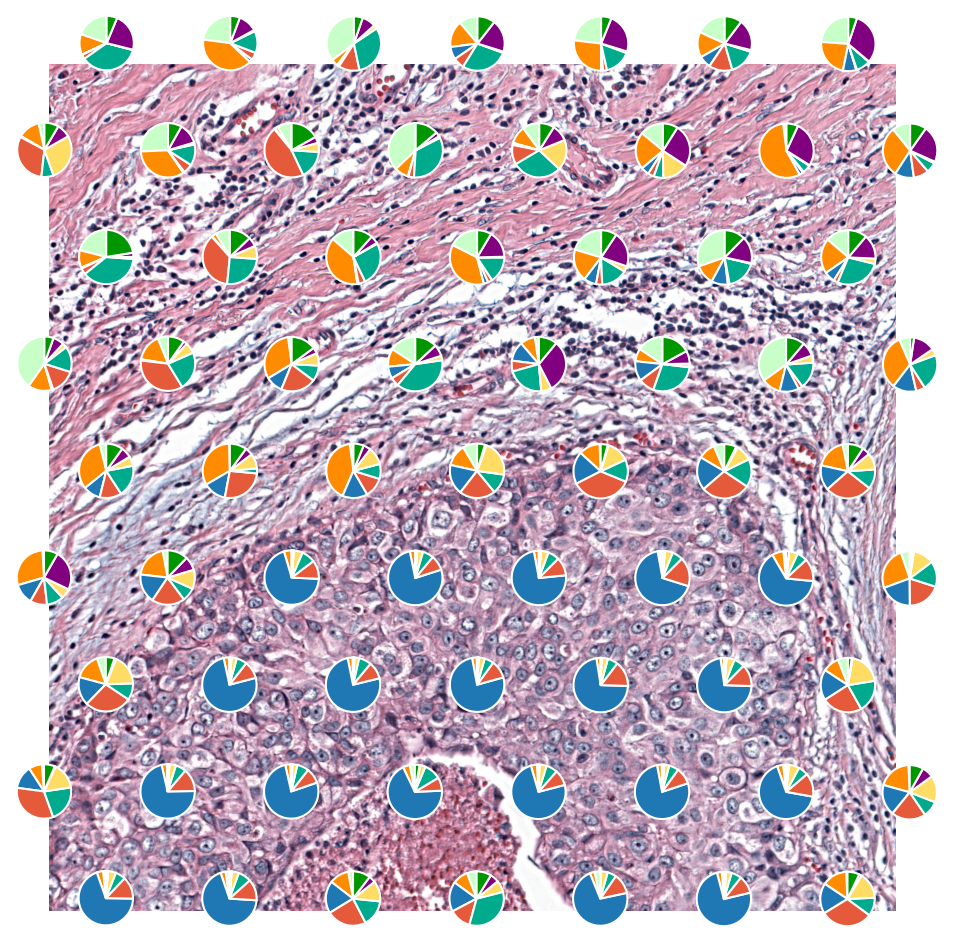

In [12]:
save(
    viewer.plot_slide(WINDOW_CROP, spot_prop_df=spot_prop_df, show_spots=True, title=""),
    "big_crop_props",
)

# HEDeST predictions

The same window, with every nucleus outlined in the colour of its predicted cell type.

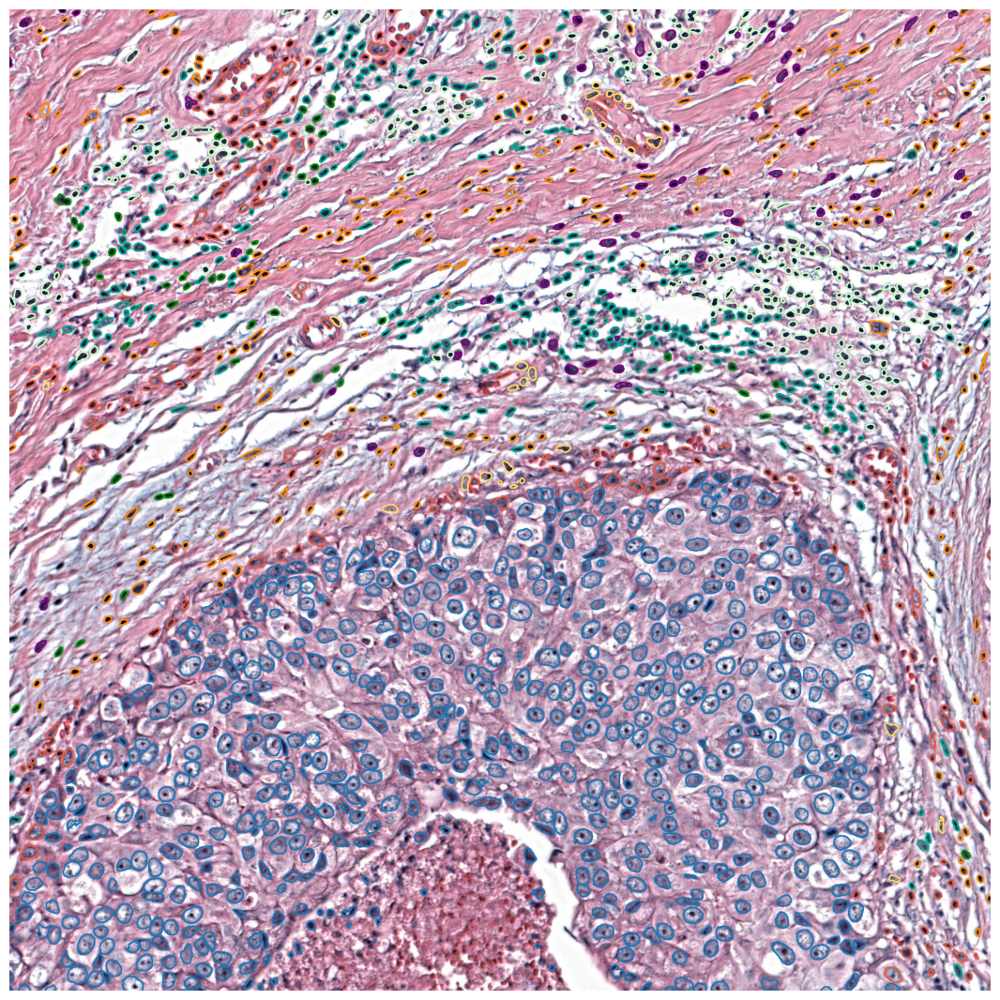

In [13]:
save(viewer.plot_seg(WINDOW_CROP, title="", legend=False), "big_crop_HEDeST")

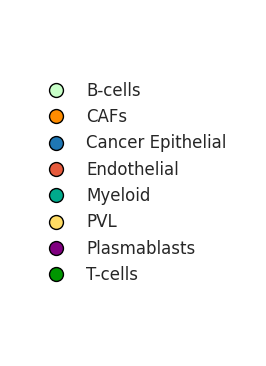

In [14]:
from hedest.analysis import plots

save(plots.plot_legend(palette), "legend")

## The whole slide **(new)**

At 27,452 x 25,233 px a nucleus covers well under a pixel, so contours cannot be drawn;
every cell becomes a coloured dot instead. This is the view the three windows above are
cut out of.

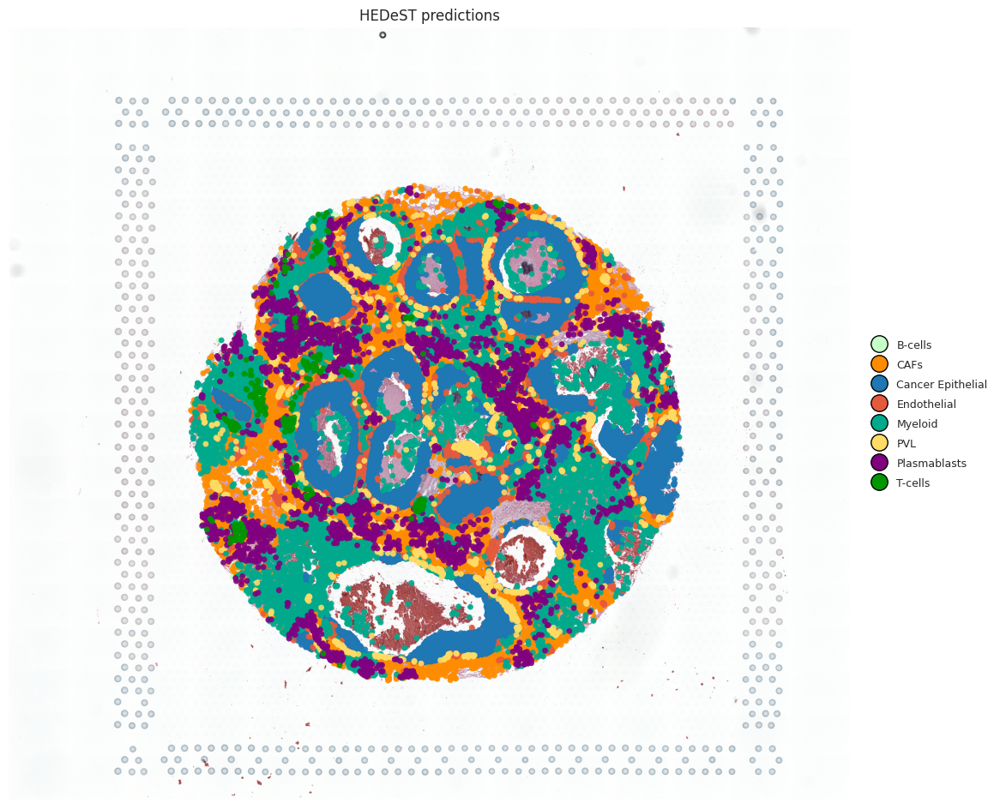

In [15]:
save(viewer.plot_celltype_map("full", title="HEDeST predictions"), "celltype_map")

And three summaries of how the predictions sit against the deconvolution they come from
**(new)**: the overall composition, the per-spot agreement cell type by cell type, and how
confidently each type is called.

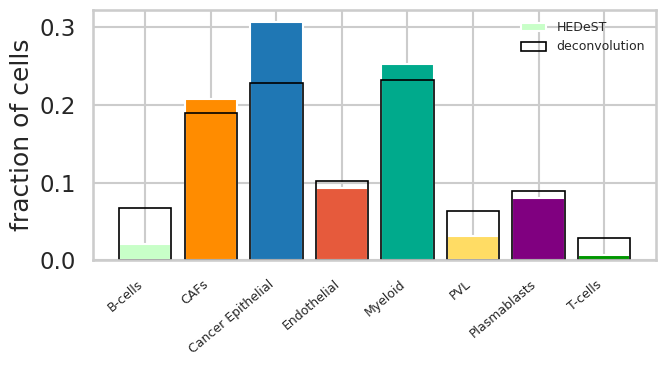

In [16]:
save(analyzer.plot_abundance(), "abundance")

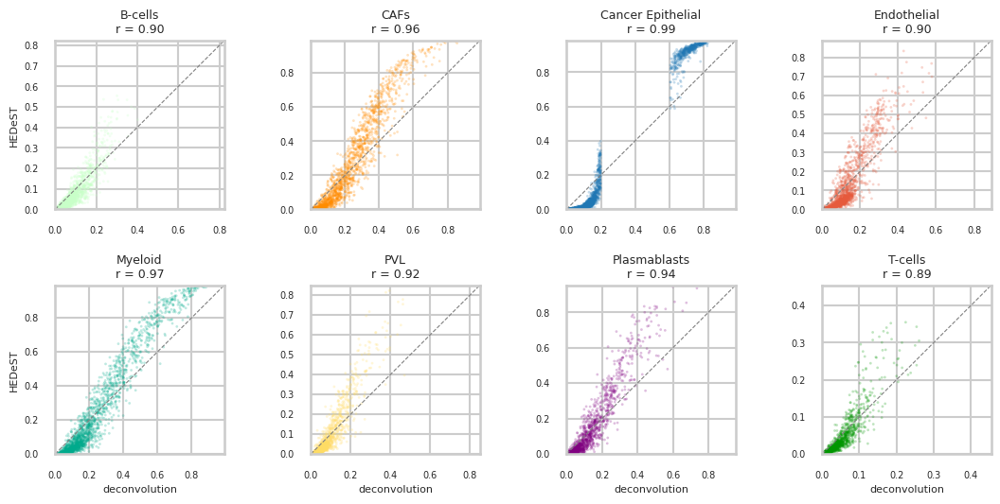

In [17]:
save(analyzer.plot_proportion_scatter(), "proportion_scatter")

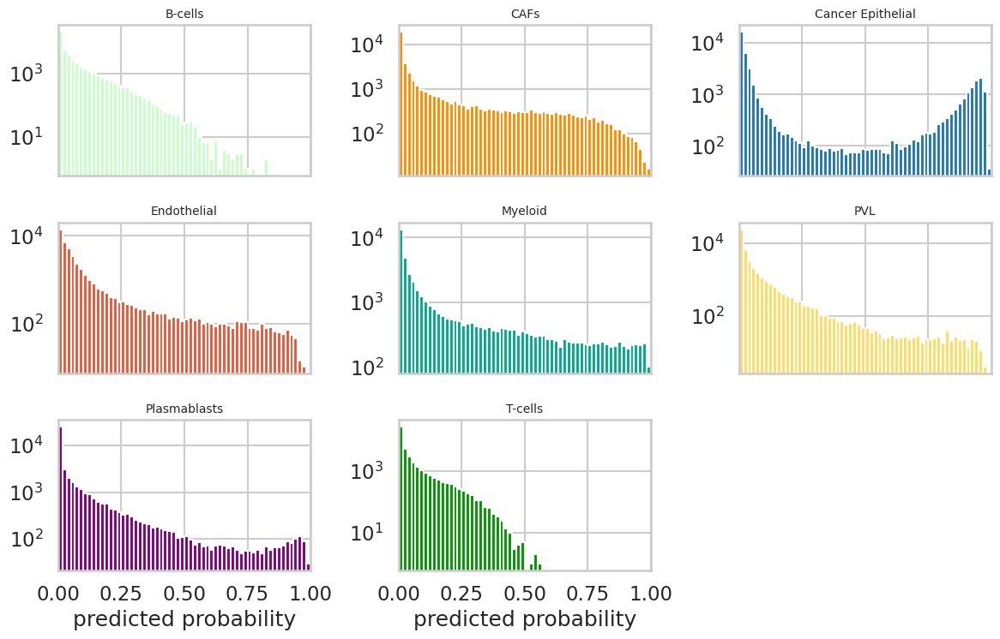

In [18]:
save(analyzer.plot_probability_histograms(), "probability_histograms")

One spot, in full **(new)**: its tissue with the nuclei drawn, the mean predicted
probability over its cells, the composition those predictions imply, and the deconvolution
they are meant to reproduce.

2026-10-14 14:29:03.044 | INFO     | hedest.analysis.pred_analyzer:plot_spot_report:891 - Randomly selected spot CTCTTCTATTGACTGG-1.


2026-10-14 14:29:04.232 | INFO     | hedest.analysis.postseg:_load_segmentation:245 - Loaded 45237 nuclei from the segmentation.


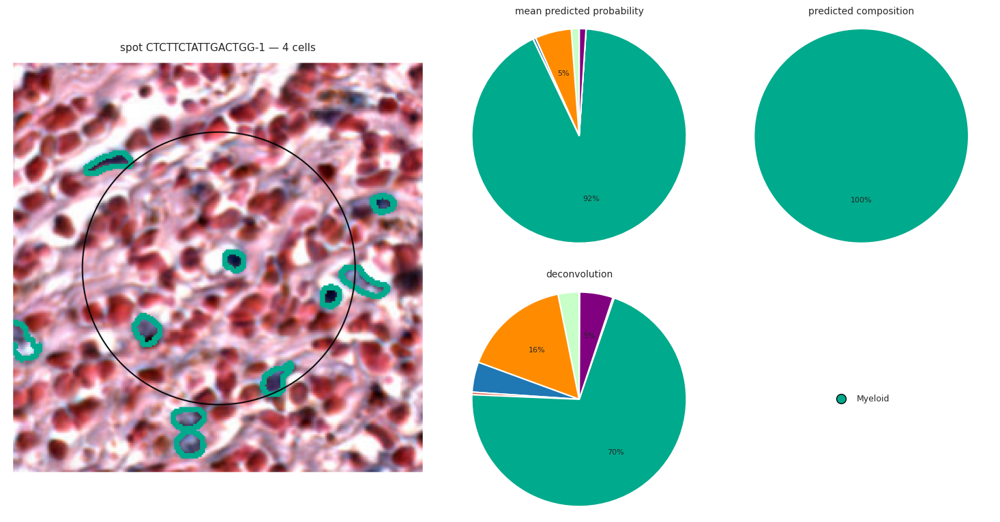

In [19]:
np.random.seed(0)
save(analyzer.plot_spot_report(), "spot_report")

# Prediction analysis

The most confident cells of each predicted type, as a gallery of nucleus crops — 90 per
type, the morphologies to compare at a glance.

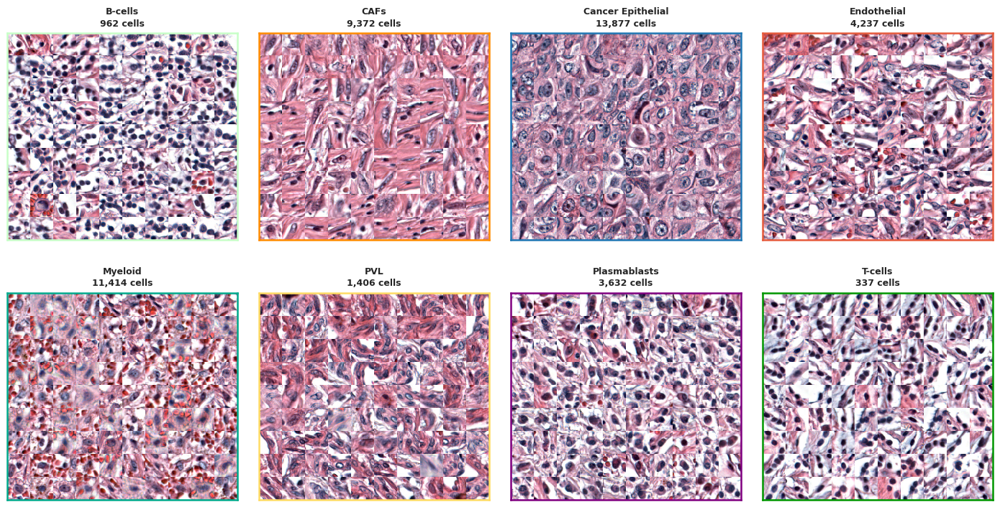

In [20]:
save(
    analyzer.plot_celltype_grid(num_rows=9, num_cols=10, selection="max", mosaic=(2, 4)),
    "grid_celltype",
)

Nucleus area per predicted cell type, in µm² now that the analyzer knows the slide's mpp,
with one-sided Mann-Whitney tests. The test results are also logged.

2026-10-14 14:29:18.057 | INFO     | hedest.analysis.pred_analyzer:compare_area:1407 - B-cells > T-cells: U=176270, p=8.388e-03 (**)
2026-10-14 14:29:18.067 | INFO     | hedest.analysis.pred_analyzer:compare_area:1407 - Plasmablasts > B-cells: U=2200010, p=1.571e-35 (***)


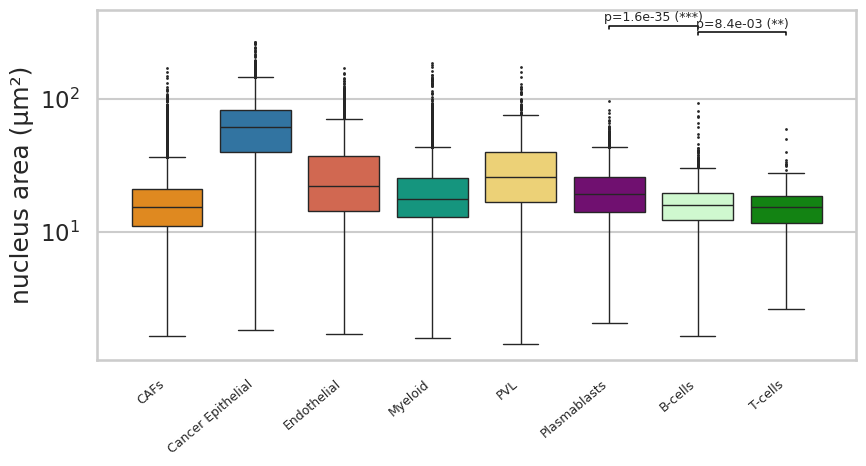

In [21]:
new_ct_list = ["CAFs", "Cancer Epithelial", "Endothelial", "Myeloid", "PVL", "Plasmablasts", "B-cells", "T-cells"]

save(
    analyzer.compare_area(
        cell_types=new_ct_list,
        tests=[["B-cells", "T-cells"], ["Plasmablasts", "B-cells"]],
    ),
    "area_comparison",
)

The Delaunay graph of the nuclei, which is what every neighbourhood below is built on.
Edges longer than 150 px (about 52 µm) are dropped, so cells are not joined across empty
tissue.

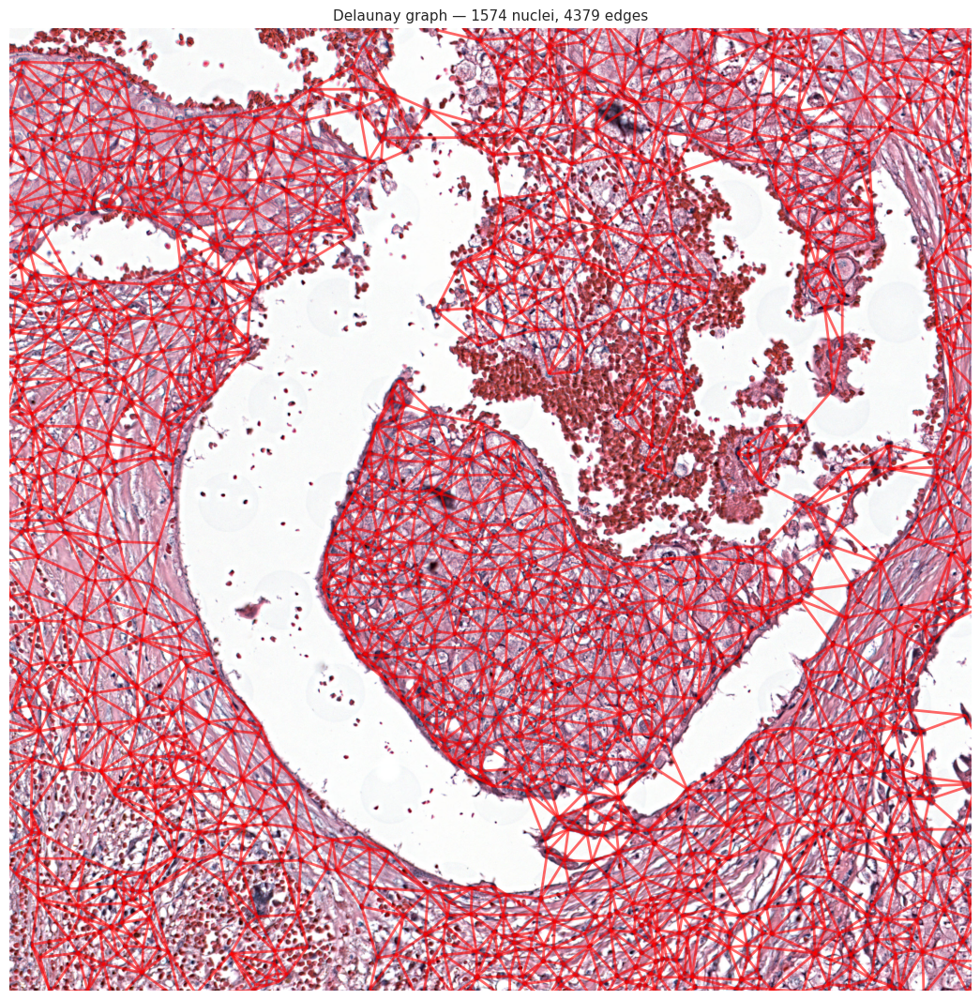

In [22]:
save(
    viewer.plot_delaunay_graph(window=WINDOW_DELAUNAY, max_distance=150, linewidth=2),
    "delaunay_graph",
)

2026-10-14 14:29:29.748 | INFO     | hedest.analysis.pred_analyzer:_edges:1045 - Delaunay graph: 45237 cells, 135659 edges.


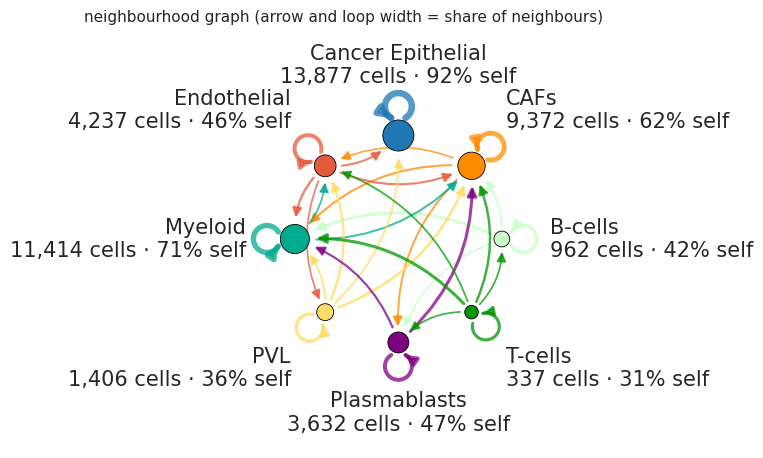

In [23]:
save(analyzer.plot_colocalization_graph(max_distance=None, fontsize=16), "coloc_graph")

This plot visualizes the neighborhood relationships between cell types. For each cell, we
identify its immediate neighbors using the Delaunay graph. We then group cells by cell type.
For a given cell type A, we calculate the average number of cells of each other cell type
found in the neighborhood of cells belonging to type A.

The arrow from cell type A to cell type B has a thickness proportional to the average number
of type B cells in the neighborhood of type A cells. A loop on a node is the share of a cell
type's neighbours that are of its own type.

The graph above uses the full triangulation, as the original study did. Cutting the long
edges at 150 px, as the niche analysis does, drops the links that only exist because the
triangulation spans empty tissue **(new)**:

2026-10-14 14:29:31.675 | INFO     | hedest.analysis.pred_analyzer:_edges:1045 - Delaunay graph: 45237 cells, 129099 edges.


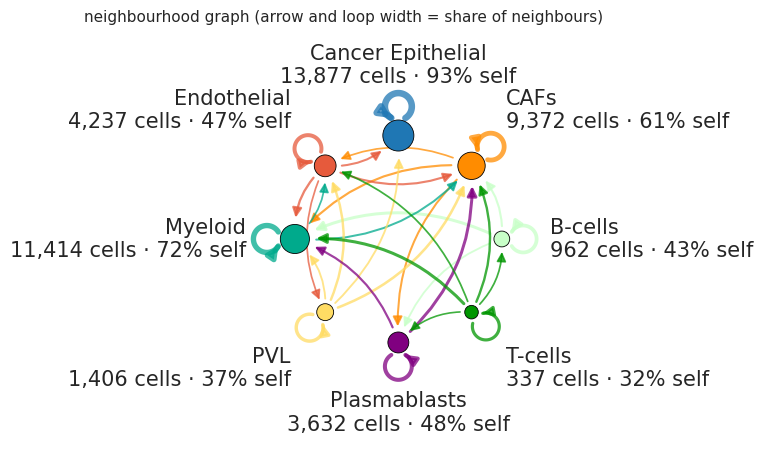

In [24]:
save(analyzer.plot_colocalization_graph(max_distance=150, fontsize=16), "coloc_graph_150px")

2026-10-14 14:29:33.549 | INFO     | hedest.analysis.pred_analyzer:_edges:1045 - Delaunay graph: 45237 cells, 135659 edges.


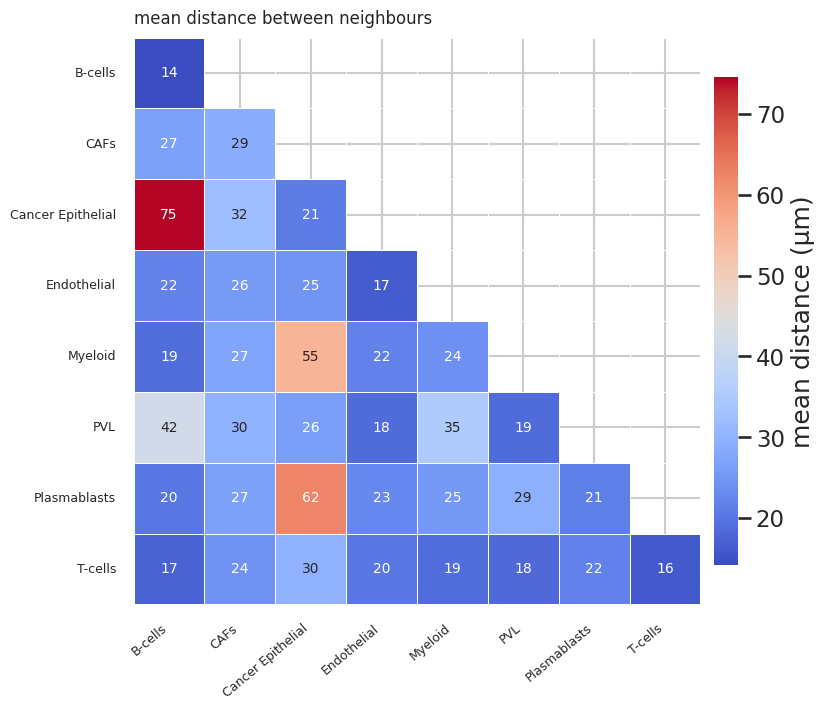

In [25]:
save(analyzer.plot_neighbor_distances(), "mean_neighbor_distances")

The same neighbourhood counts as a heatmap, which reads the exact numbers off **(new)**:

2026-10-14 14:29:35.821 | INFO     | hedest.analysis.pred_analyzer:_edges:1045 - Delaunay graph: 45237 cells, 129099 edges.


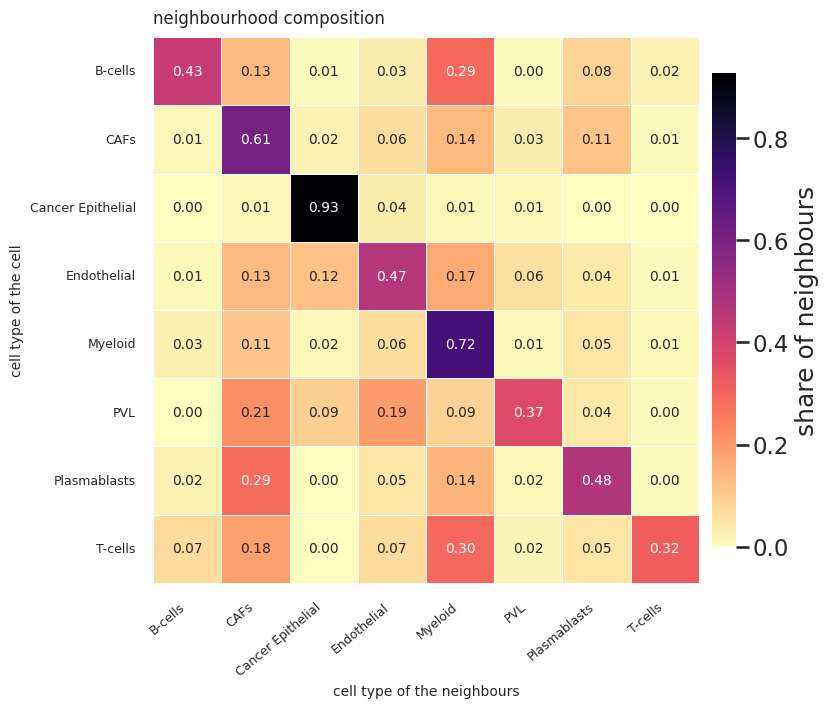

In [26]:
save(analyzer.plot_neighborhood_composition(max_distance=150), "neighborhood_composition")

# Cluster analysis
## Spot-level clustering

In order to see if HEDeST brings new information to deconvolution, we first need to perform
the clustering analysis on spot-level proportions.

In [27]:
# Gaussian mixture, with the number of components chosen by BIC
lowest_bic = np.inf
best_gmm = None
n_components_range = range(2, 50)

df_props = spot_prop_df.copy()

for n_components in n_components_range:
    gmm = GaussianMixture(n_components=n_components, covariance_type="full", random_state=42)
    gmm.fit(df_props.values)
    bic = gmm.bic(df_props.values)
    if bic < lowest_bic:
        lowest_bic = bic
        best_gmm = gmm

cluster_labels = best_gmm.predict(df_props.values)
n_clusters = best_gmm.n_components

# --- Compute centroids ---
cluster_series = pd.Series(cluster_labels, index=df_props.index, name="cluster")
df_with_clusters = df_props.join(cluster_series)
df_with_clusters = df_with_clusters[df_with_clusters["cluster"] != -1]
centroids = df_with_clusters.groupby("cluster").mean()

# --- Add to adata ---
adata.obs["gmm_clusters"] = cluster_series.astype(str)

print(f"{n_clusters} clusters, BIC {lowest_bic:.0f}")
centroids.round(3)

11 clusters, BIC -85192


,B-cells,CAFs,Cancer Epithelial,Endothelial,Myeloid,PVL,Plasmablasts,T-cells
cluster,,,,,,,,
0,0.020,0.039,0.703,0.114,0.072,0.041,0.006,0.006
1,0.094,0.305,0.125,0.044,0.194,0.032,0.164,0.042
2,0.056,0.187,0.019,0.007,0.631,0.003,0.096,0.002
3,0.161,0.033,0.130,0.049,0.525,0.037,0.024,0.041
4,0.046,0.223,0.103,0.091,0.377,0.107,0.049,0.004
5,0.015,0.497,0.101,0.070,0.127,0.063,0.102,0.026
6,0.093,0.136,0.189,0.261,0.142,0.138,0.020,0.021
7,0.073,0.178,0.040,0.136,0.221,0.069,0.230,0.053
8,0.011,0.214,0.089,0.260,0.093,0.203,0.094,0.036


The spot coordinates are flipped for the scanpy views only, on a separate `obsm` key:
`adata.obsm['spatial']` itself is left alone, because the slide views above read it for the
spot centres.

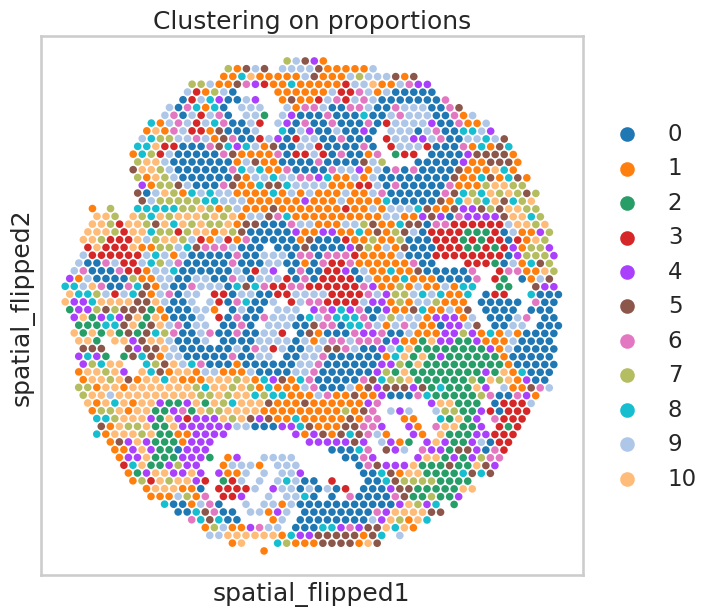

In [28]:
FIGSIZE = (7, 7)
rcParams["figure.figsize"] = FIGSIZE

adata.obsm["spatial_flipped"] = np.column_stack(
    [adata.obsm["spatial"][:, 0].astype(int), -adata.obsm["spatial"][:, 1].astype(int)]
)

fig = sc.pl.embedding(
    adata,
    basis="spatial_flipped",
    color="gmm_clusters",
    s=120,
    title="Clustering on proportions",
    show=False,
    return_fig=True,
)
save(fig, "proportions_clusters")

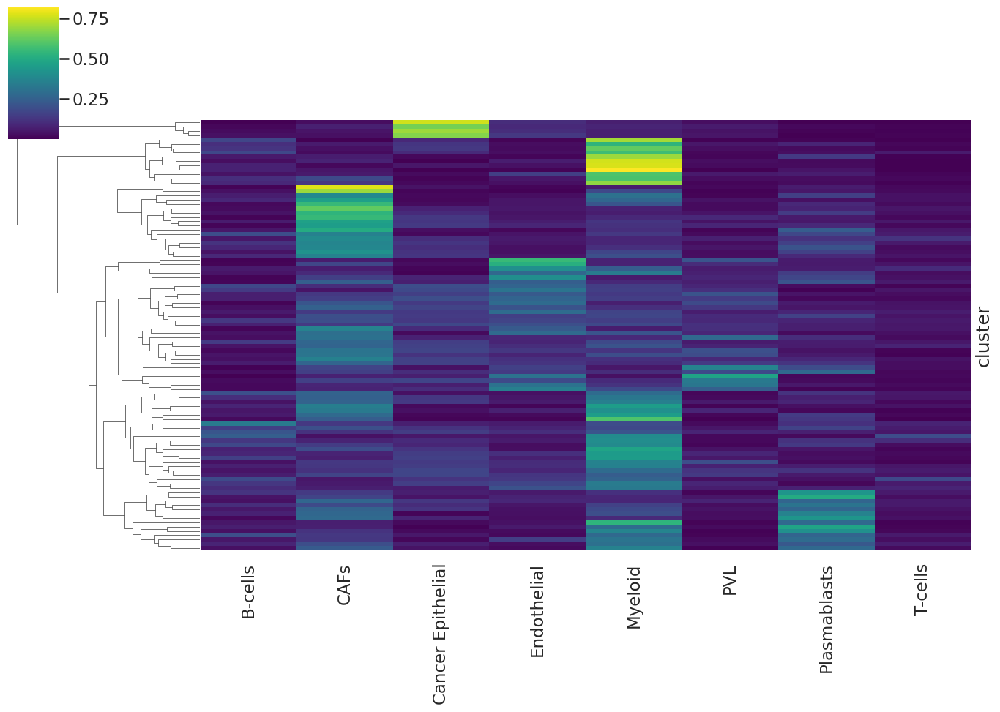

In [29]:
# --- Over-clustering, then a hierarchical view of the cluster compositions ---
n_clusters = 100
gmm = GaussianMixture(n_components=n_clusters, covariance_type="full", random_state=42)
cluster_labels = gmm.fit_predict(spot_prop_df.values)

cluster_series = pd.Series(cluster_labels, index=spot_prop_df.index, name="cluster")
centroids = spot_prop_df.join(cluster_series).groupby("cluster").mean()

grid = sns.clustermap(
    centroids,
    method="average",
    metric="euclidean",
    cmap="viridis",
    figsize=(14, 10),
    xticklabels=True,
    yticklabels=False,
    col_cluster=False,
)
save(grid.figure, "neighborhood_clusters_heatmap")

### Spatially-aware clustering

The same mixture, on proportions smoothed over each spot's six nearest neighbours, so that
a cluster has to be spatially coherent to survive.

In [30]:
seed = 42
np.random.seed(seed)

# -------------------------------
# Parameters
# -------------------------------
n_neighbors = 6      # number of spatial neighbors to consider
lambda_ = 0.5        # weight for neighbor contributions in spatial smoothing
n_components_range = range(2, 50)

coords = adata.obsm["spatial"]

# -------------------------------
# Build neighbor graph
# -------------------------------
nbrs = NearestNeighbors(n_neighbors=n_neighbors, algorithm="ball_tree").fit(coords)
distances, indices = nbrs.kneighbors(coords)

# -------------------------------
# Row-normalised adjacency
# -------------------------------
n_spots = spot_prop_df.shape[0]
W = np.zeros((n_spots, n_spots))
for i, neighbors_of_i in enumerate(indices):
    W[i, neighbors_of_i] = 1
W = W / W.sum(axis=1, keepdims=True)

# -------------------------------
# Spatially smoothed features
# -------------------------------
X = spot_prop_df.values
spatial_features = X + lambda_ * W @ X

# -------------------------------
# GMM clustering
# -------------------------------
lowest_bic = np.inf
best_gmm = None

for n_components in n_components_range:
    gmm = GaussianMixture(n_components=n_components, covariance_type="full", random_state=42)
    gmm.fit(spatial_features)
    bic = gmm.bic(spatial_features)
    if bic < lowest_bic:
        lowest_bic = bic
        best_gmm = gmm

cluster_labels = best_gmm.predict(spatial_features)
adata.obs["spatial_gmm_clusters"] = pd.Series(cluster_labels, index=spot_prop_df.index).astype(str)

cluster_series = pd.Series(cluster_labels, index=spot_prop_df.index, name="cluster")
centroids = spot_prop_df.join(cluster_series).groupby("cluster").mean()

print(f"{best_gmm.n_components} spatially-aware clusters, BIC {lowest_bic:.0f}")
centroids.round(3)

13 spatially-aware clusters, BIC -71888


,B-cells,CAFs,Cancer Epithelial,Endothelial,Myeloid,PVL,Plasmablasts,T-cells
cluster,,,,,,,,
0,0.016,0.031,0.720,0.117,0.070,0.038,0.003,0.006
1,0.110,0.303,0.118,0.043,0.206,0.027,0.140,0.053
2,0.158,0.033,0.134,0.079,0.472,0.050,0.017,0.059
3,0.018,0.487,0.108,0.074,0.125,0.066,0.094,0.028
4,0.016,0.198,0.062,0.247,0.130,0.189,0.123,0.035
5,0.094,0.137,0.187,0.261,0.142,0.135,0.022,0.022
6,0.082,0.220,0.107,0.092,0.126,0.065,0.264,0.042
7,0.027,0.053,0.674,0.108,0.076,0.046,0.011,0.006
8,0.137,0.032,0.079,0.012,0.700,0.012,0.025,0.003


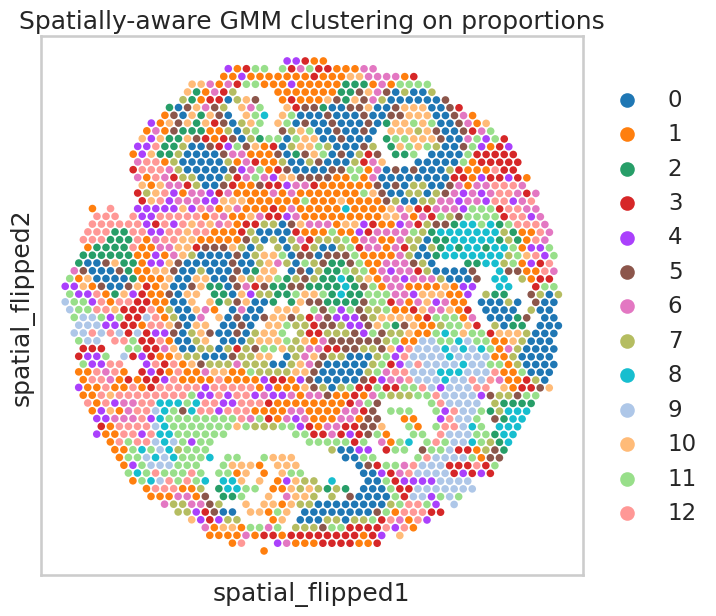

In [31]:
rcParams["figure.figsize"] = FIGSIZE

fig = sc.pl.embedding(
    adata,
    basis="spatial_flipped",
    color="spatial_gmm_clusters",
    s=120,
    title="Spatially-aware GMM clustering on proportions",
    show=False,
    return_fig=True,
)
save(fig, "spatial_proportions_clusters")

## Cell-level clustering

Here, we perform a clustering analysis to study neighborhood patterns. Starting from
single-cell annotations, we "zoom out" to examine clusters defined by the composition of
each cell's local neighborhood. For every cell, we compute a vector representing the
proportions of each cell type in its neighborhood. We then cluster the cells based on these
proportion vectors.

This is the part of the study the single-cell resolution is for: the spot clusters above
cannot see it, because a niche is smaller than a spot.

In [32]:
from collections import Counter

orig_types = analyzer.labels.to_dict()
neighbors = analyzer.neighbors(max_distance=150)

# --- Build neighbor proportion vectors ---
rows = []
cell_ids = []

for cell_id, neigh_ids in neighbors.items():
    neigh_types = [orig_types[nid] for nid in neigh_ids if nid in orig_types]
    if not neigh_types:
        continue

    counts = Counter(neigh_types)
    total = sum(counts.values())
    rows.append([counts.get(ct, 0) / total for ct in ct_list])
    cell_ids.append(cell_id)

df_props = pd.DataFrame(rows, index=cell_ids, columns=ct_list)
print(f"{len(df_props)} of {len(analyzer.labels)} cells have at least one neighbour within 150 px")
df_props.head()

45176 of 45237 cells have at least one neighbour within 150 px


,B-cells,CAFs,Cancer Epithelial,Endothelial,Myeloid,PVL,Plasmablasts,T-cells
0,0.0,0.000000,0.0,1.000000,0.000000,0.0,0.0,0.0
1,0.0,0.333333,0.0,0.666667,0.000000,0.0,0.0,0.0
34990,0.0,0.142857,0.0,0.714286,0.142857,0.0,0.0,0.0
34995,0.0,0.000000,0.0,1.000000,0.000000,0.0,0.0,0.0
34996,0.0,0.000000,0.0,0.800000,0.200000,0.0,0.0,0.0


In [33]:
# --- Clustering, number of components by BIC ---
lowest_bic = np.inf
best_gmm = None
n_components_range = range(2, 10)

for n_components in n_components_range:
    gmm = GaussianMixture(n_components=n_components, covariance_type="full", random_state=45)
    gmm.fit(df_props.values)
    bic = gmm.bic(df_props.values)
    if bic < lowest_bic:
        lowest_bic = bic
        best_gmm = gmm

cluster_labels = best_gmm.predict(df_props.values)
print(f"{best_gmm.n_components} niches, sizes {np.bincount(cluster_labels).tolist()}")

9 niches, sizes [166, 11044, 10369, 9714, 2884, 2033, 7814, 689, 463]


### Merging the closest pair

The mixture leaves one niche that is a thin shaving off another: same composition, a few
hundred cells. The original study merged it by hand. Here the pair is **computed** — the two
centroids at the smallest Euclidean distance — and the smaller of the two is absorbed into
the larger, so the step survives a clustering that comes out differently.

In [34]:
from itertools import combinations

raw_centroids = df_props.assign(cluster=cluster_labels).groupby("cluster").mean()
sizes = np.bincount(cluster_labels)

distance, left, right = min(
    (np.linalg.norm(raw_centroids.loc[a] - raw_centroids.loc[b]), a, b)
    for a, b in combinations(raw_centroids.index, 2)
)
absorbed, into = sorted((left, right), key=lambda c: sizes[c])
print(f"merging niche {absorbed} ({sizes[absorbed]} cells) into {into} ({sizes[into]} cells), d = {distance:.3f}")

# --- Merge clusters ---
new_labels = cluster_labels.copy()
new_labels[cluster_labels == absorbed] = into
cluster_labels = new_labels

# --- Relabel so the ids are 0..n-1 again ---
unique = sorted(np.unique(cluster_labels))
label_map = {old: new for new, old in enumerate(unique)}
cluster_labels = np.array([label_map[label] for label in cluster_labels])
n_clusters = len(unique)

print(f"{n_clusters} niches, sizes {np.bincount(cluster_labels).tolist()}")

merging niche 0 (166 cells) into 6 (7814 cells), d = 0.221
8 niches, sizes [11044, 10369, 9714, 2884, 2033, 7980, 689, 463]


In [35]:
# --- Compute centroids ---
cluster_series = pd.Series(cluster_labels, index=df_props.index, name="cluster")
df_with_clusters = df_props.join(cluster_series)
df_with_clusters = df_with_clusters[df_with_clusters["cluster"] != -1]
centroids = df_with_clusters.groupby("cluster").mean()
centroids.round(3)

,B-cells,CAFs,Cancer Epithelial,Endothelial,Myeloid,PVL,Plasmablasts,T-cells
cluster,,,,,,,,
0,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000
1,0.000,0.132,0.000,0.168,0.700,0.000,0.000,0.000
2,0.000,0.568,0.000,0.000,0.172,0.000,0.260,0.000
3,0.118,0.244,0.000,0.209,0.160,0.000,0.270,0.000
4,0.280,0.091,0.000,0.060,0.446,0.000,0.000,0.123
5,0.002,0.168,0.353,0.207,0.121,0.147,0.002,0.000
6,0.000,0.274,0.029,0.108,0.028,0.244,0.312,0.007
7,0.063,0.201,0.000,0.065,0.183,0.115,0.199,0.172


### Drawing the niches on the slide

The niches get their own palette, drawn from `Dark2`, `tab20b` and `tab20c` as in the
original, and the cells with no neighbour within 150 px are left out as `unassigned`.

In [36]:
# --- Color dictionary ---
cmap_list = [plt.get_cmap(name) for name in ["Dark2", "tab20b", "tab20c"]]
colors = list(chain.from_iterable(cmap.colors for cmap in cmap_list))

niche_names = [f"niche {i}" for i in range(n_clusters)]
niche_colors = {name: colors[i % len(colors)] for i, name in enumerate(niche_names)}
niche_colors["unassigned"] = (0.78, 0.78, 0.78)
niche_palette = Palette.from_colors(niche_colors, names=niche_names + ["unassigned"])

# --- Replace cell types with niches, over every segmented cell ---
niche_labels = pd.Series("unassigned", index=analyzer.labels.index, name="niche")
niche_labels.loc[df_props.index] = [f"niche {label}" for label in cluster_labels]

niche_labels.value_counts().reindex(niche_palette.names)

niche
niche 0       11044
niche 1       10369
niche 2        9714
niche 3        2884
niche 4        2033
niche 5        7980
niche 6         689
niche 7         463
unassigned       61
Name: count, dtype: int64

The window is nearly the whole slide, so the niches are drawn as a cell-type map rather
than as contours: at that downsample a nucleus is a fraction of a pixel and an outline
cannot be seen. The original scaled its contours by 4 to work around this; the map shows
the same thing without inventing a cell size.

2026-10-14 14:32:39.702 | INFO     | hedest.analysis.postseg:_load_segmentation:245 - Loaded 45237 nuclei from the segmentation.


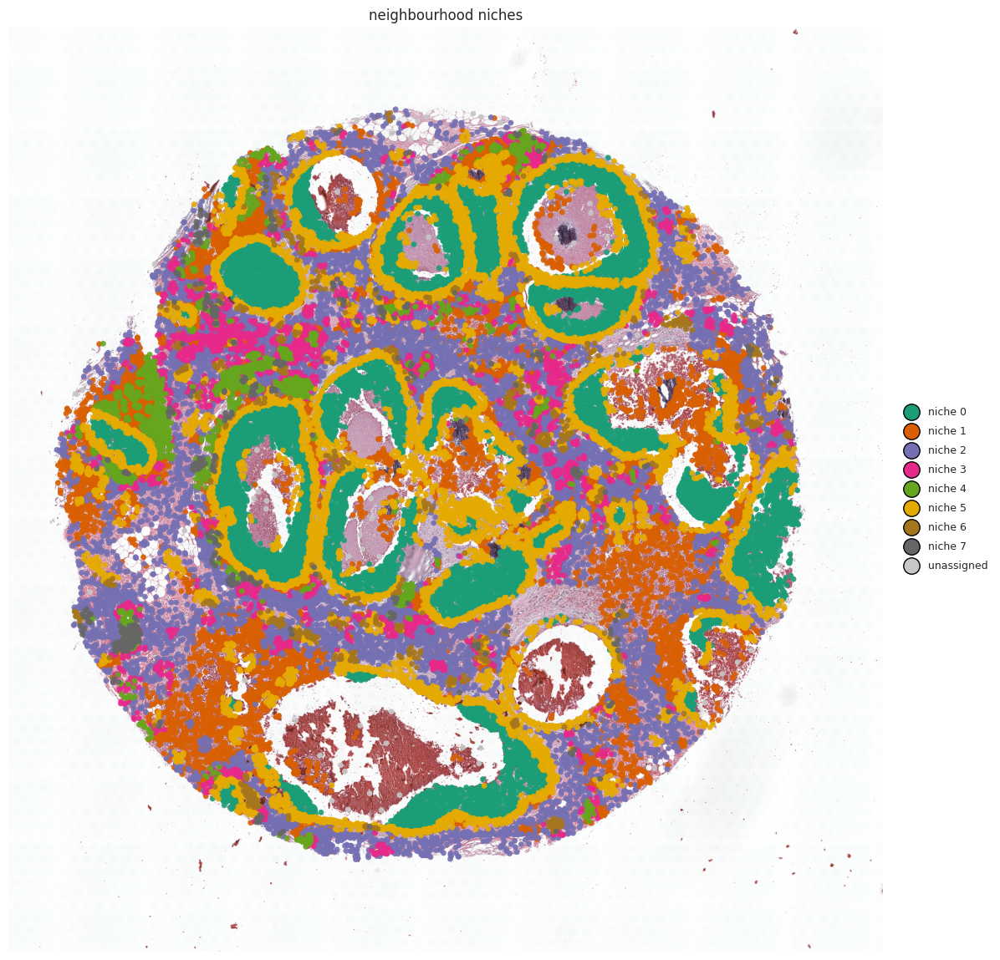

In [37]:
niche_viewer = analyzer.visualizer(labels=niche_labels, palette=niche_palette)

save(
    niche_viewer.plot_celltype_map(WINDOW_SLIDE, title="neighbourhood niches"),
    "neighborhood_clusters",
)

And the niches one panel at a time, on the 2,000 px window where contours are readable
**(new)** — which of them is where, without eight colours competing in one image.

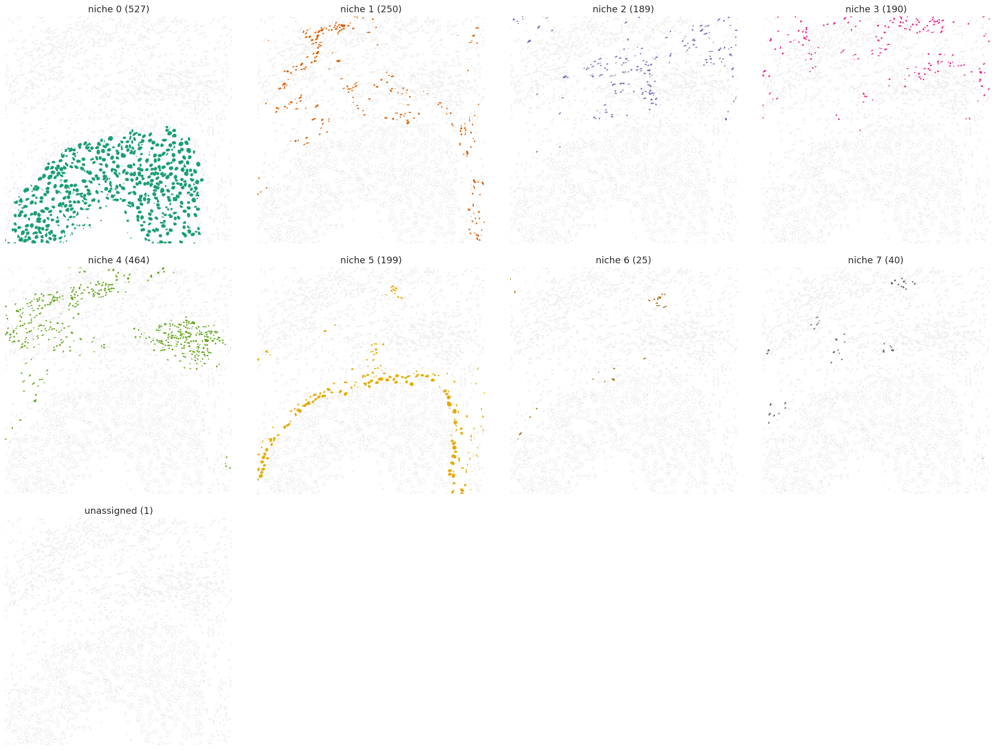

In [38]:
save(
    niche_viewer.plot_seg_overlays(WINDOW_CROP, max_cols=4, panel_size=(5.0, 5.0)),
    "neighborhood_clusters_panels",
)

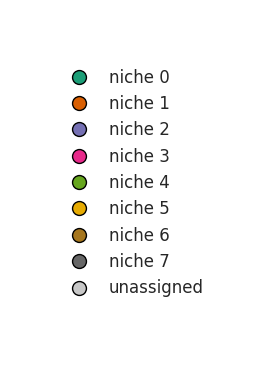

In [39]:
save(plots.plot_legend(niche_palette), "legend_neighbors")

### What each niche is made of

The centroid of a niche is the mean cell-type composition of the neighbourhoods it groups.
The original showed one of them as a pie; all of them are shown here, as pies and as stacked
bars, so a niche can be named rather than looked up.

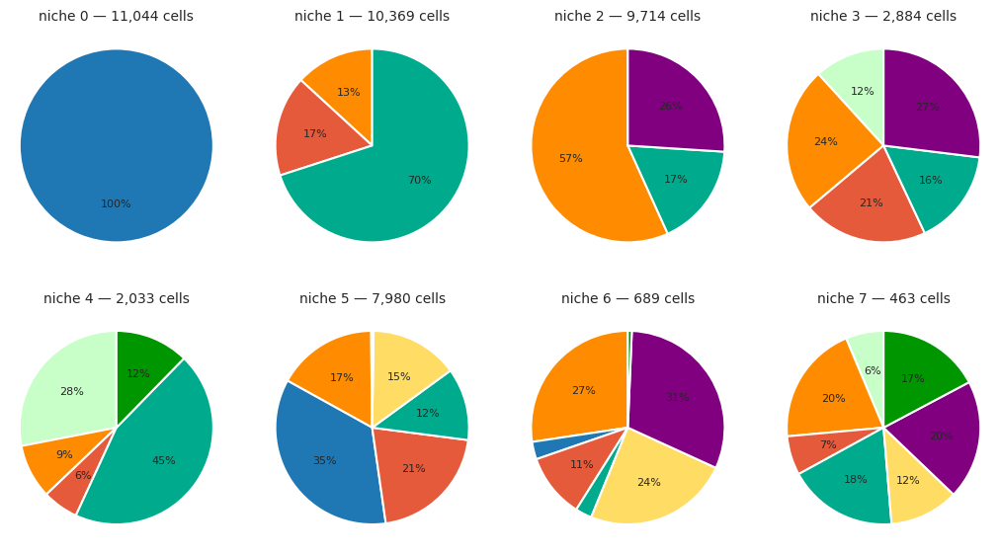

In [40]:
n_cols = 4
n_rows = int(np.ceil(n_clusters / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.2 * n_cols, 3.4 * n_rows), squeeze=False)
for ax in axes.flat:
    ax.axis("off")

for position, cluster_id in enumerate(centroids.index):
    plots.plot_pie_chart(
        axes.flat[position],
        centroids.loc[cluster_id],
        palette,
        title=f"niche {cluster_id} — {int((cluster_labels == cluster_id).sum()):,} cells",
    )

save(fig, "cluster_centroids")

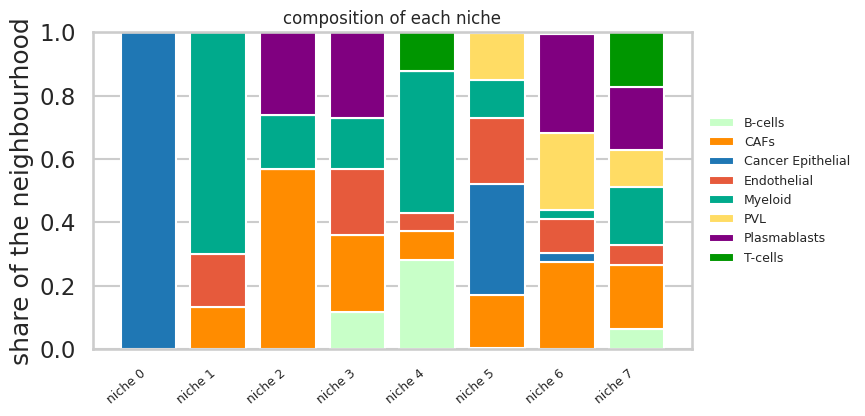

In [41]:
save(
    plots.plot_stacked_bars(
        centroids.rename(index=lambda i: f"niche {i}"),
        palette,
        ylabel="share of the neighbourhood",
        title="composition of each niche",
    ),
    "cluster_centroids_bars",
)

The single niche of the original figure, kept on its own — the largest one:

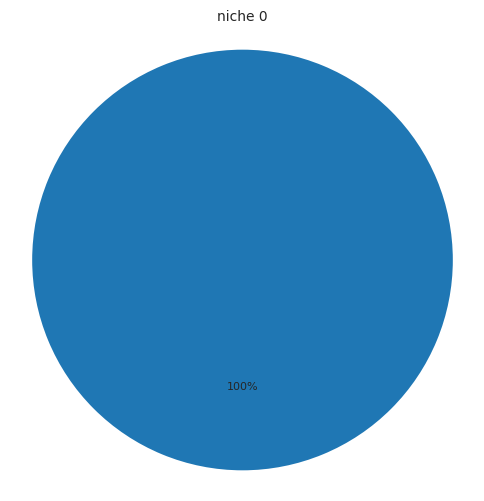

In [42]:
cluster_id = int(pd.Series(cluster_labels).value_counts().idxmax())

fig, ax = plt.subplots(figsize=(6, 6))
plots.plot_pie_chart(ax, centroids.loc[cluster_id], palette, title=f"niche {cluster_id}")
save(fig, f"cluster_{cluster_id}_centroid")

### Over-clustering the neighbourhoods

As at spot level: many more components than there are niches, then a hierarchical view of
their compositions. It says whether the eight niches above are a real partition of the
neighbourhood space or a coarse cut through a continuum.

500 non-empty components out of 500


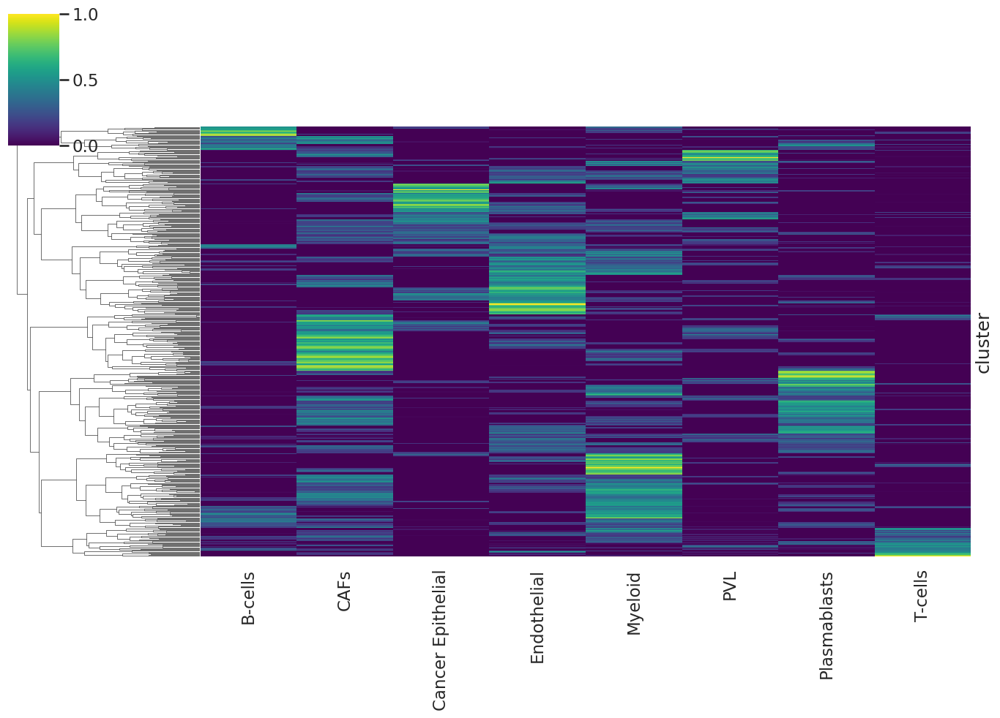

In [43]:
n_over = 500
gmm = GaussianMixture(n_components=n_over, covariance_type="full", random_state=42)
over_labels = gmm.fit_predict(df_props.values)

over_centroids = df_props.assign(cluster=over_labels).groupby("cluster").mean()
print(f"{len(over_centroids)} non-empty components out of {n_over}")

grid = sns.clustermap(
    over_centroids,
    method="average",
    metric="euclidean",
    cmap="viridis",
    figsize=(14, 10),
    xticklabels=True,
    yticklabels=False,
    col_cluster=False,
)
save(grid.figure, "neighborhood_cell_level_clusters_heatmap")

---

## Exports

Two GeoJSONs sit next to this notebook, written with the same palette so they overlay in
QuPath:

* **`spot_pies.geojson`** — the DestVI proportions, one pie per spot at its real diameter,
  wedges starting at twelve o'clock and following the columns of the table (annotations);
* **`hedest_predictions.geojson`** — the 45,237 nuclei with their aggregated HEDeST cell
  type (detections).

Loaded together, `A` shows or hides the pies, `D` the cells, `F` fills them.

Every figure of this notebook is in `figures/`, as PNG and SVG.